<a href="https://colab.research.google.com/github/RaihanDaffa04/PCVK_Ganjil2026/blob/main/Week07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

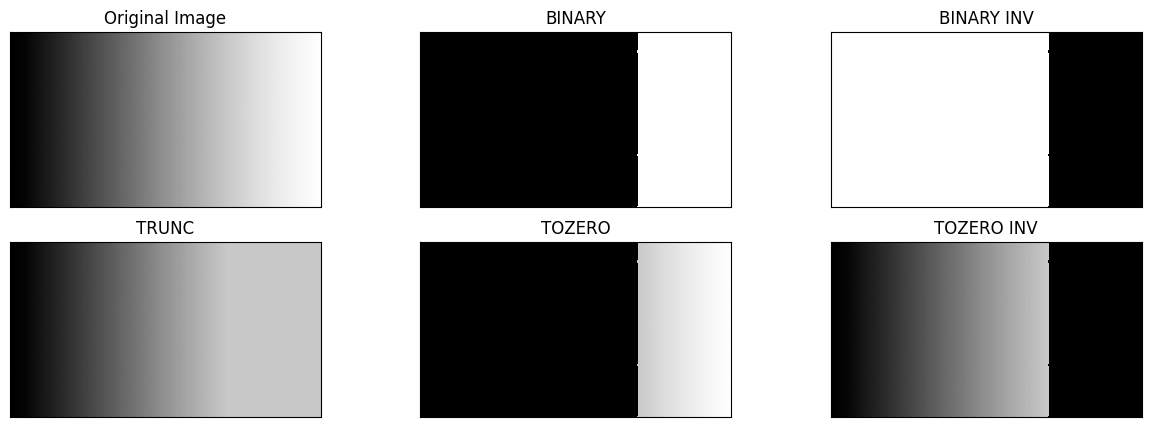

In [8]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

filename = '/content/drive/MyDrive/PCVK/Images/gradient.jpg'
img = cv.imread(filename, 0)

thresh = 200
maxval = 255

thresh1 = np.zeros_like(img)
thresh1[img > thresh] = maxval

thresh2 = np.full_like(img, maxval)
thresh2[img > thresh] = 0

thresh3 = img.copy()
thresh3[img > thresh] = thresh

thresh4 = img.copy()
thresh4[img <= thresh] = 0

thresh5 = img.copy()
thresh5[img > thresh] = 0

titles = ['Original Image', 'BINARY', 'BINARY INV', 'TRUNC', 'TOZERO', 'TOZERO INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255, interpolation='nearest')
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])
plt.show()

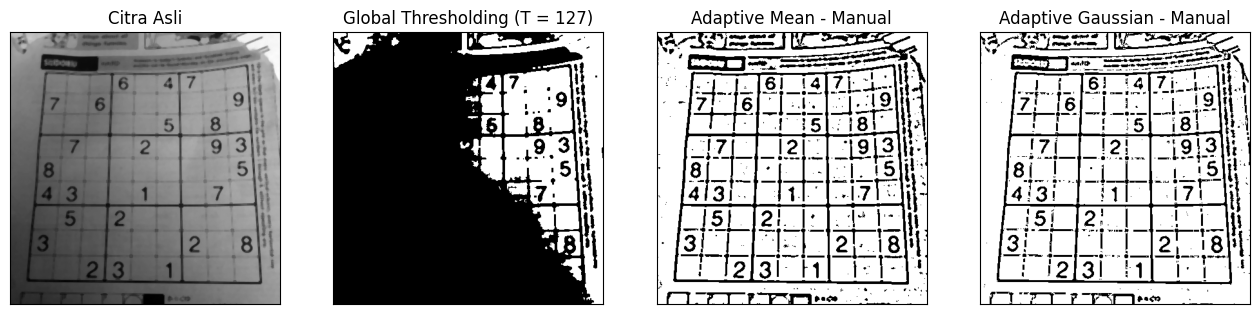

In [14]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

filename = '/content/drive/MyDrive/PCVK/Images/sudoku-original.jpg'
img_bgr = cv.imread(filename)
if img_bgr is not None:
    img_blur = cv.medianBlur(img_bgr, 5)
    gray = cv.cvtColor(img_blur, cv.COLOR_BGR2GRAY)
else:
    gray = cv.imread(filename, 0)

h, w = gray.shape
block_size = 11
C = 2
pad = block_size // 2

th_global = np.zeros_like(gray)
th_global[gray > 127] = 255
th_global[gray <= 127] = 0

padded_mean = np.pad(gray, pad, mode='reflect').astype(np.float32)
local_mean = np.zeros((h, w), dtype=np.float32)

for y in range(h):
    for x in range(w):
        window = padded_mean[y:y+block_size, x:x+block_size]
        local_mean[y, x] = np.mean(window)

th_mean_manual = np.zeros_like(gray)
th_mean_manual[gray > (local_mean - C)] = 255

k = block_size // 2
ax = np.arange(-k, k + 1)
xx, yy = np.meshgrid(ax, ax)
kernel = np.exp(-(xx**2 + yy**2) / (2 * (2.0**2)))
kernel = kernel / np.sum(kernel)

padded_gauss = np.pad(gray, pad, mode='reflect').astype(np.float32)
local_gauss = np.zeros((h, w), dtype=np.float32)

for y in range(h):
    for x in range(w):
        window = padded_gauss[y:y+block_size, x:x+block_size]
        local_gauss[y, x] = np.sum(window * kernel)

th_gauss_manual = np.zeros_like(gray)
th_gauss_manual[gray > (local_gauss - C)] = 255

titles = ['Citra Asli', 'Global Thresholding (T = 127)', 'Adaptive Mean - Manual', 'Adaptive Gaussian - Manual']
images = [gray, th_global, th_mean_manual, th_gauss_manual]

plt.figure(figsize=(16, 6))
for i in range(len(images)):
    plt.subplot(1, 4, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])
plt.show()

Threshold Otsu terpilih: 93


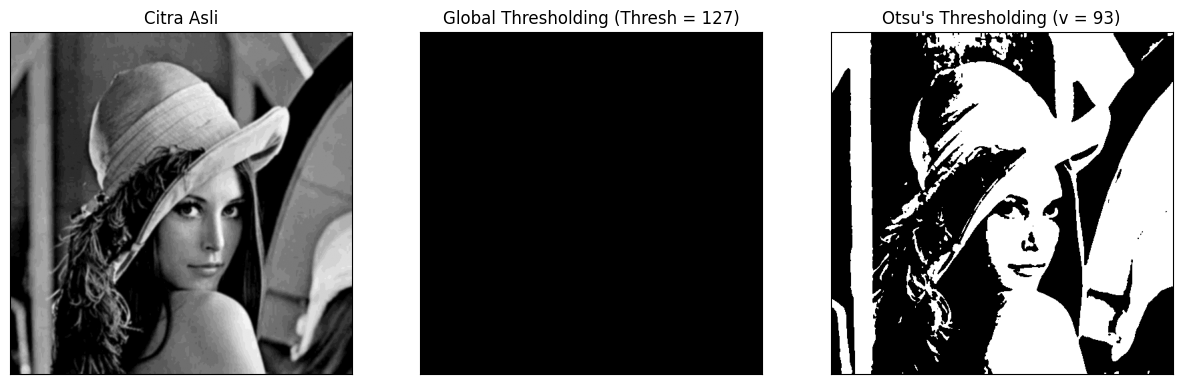

Threshold Otsu terpilih: 166


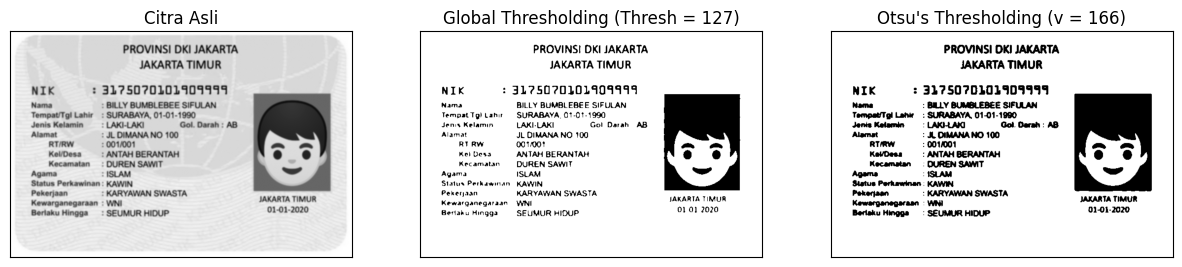

In [16]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0:
            continue
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = gray.copy()
    print("Threshold Otsu terpilih:", final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray <= final_thresh] = 0
    return final_img, final_thresh

filename_lena = '/content/drive/MyDrive/PCVK/Images/lena_gs_lc2.jpg'
img_lena = cv.imread(filename_lena, 0)
blur_lena = cv.GaussianBlur(img_lena, (5, 5), 0)
thresh_val = 127

otsu_biner_lena, otsu_thresh_lena = otsu(blur_lena)
x_lena = "Otsu's Thresholding (v = " + str(otsu_thresh_lena) + ")"
ret_lena, th1_lena = cv.threshold(blur_lena, thresh_val, 255, cv.THRESH_BINARY)

titles_lena = ['Citra Asli', f'Global Thresholding (Thresh = {thresh_val})', x_lena]
citra3_lena = [blur_lena, th1_lena, otsu_biner_lena]

plt.figure(figsize=(15, 5))
for i in range(len(citra3_lena)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(citra3_lena[i], 'gray')
    plt.title(titles_lena[i])
    plt.xticks([])
    plt.yticks([])
plt.show()

filename_ktp = '/content/drive/MyDrive/PCVK/Images/ktp_fulan.jpg'
img_ktp = cv.imread(filename_ktp, 0)
blur_ktp = cv.GaussianBlur(img_ktp, (5, 5), 0)

otsu_biner_ktp, otsu_thresh_ktp = otsu(blur_ktp)
x_ktp = "Otsu's Thresholding (v = " + str(otsu_thresh_ktp) + ")"
ret_ktp, th1_ktp = cv.threshold(blur_ktp, thresh_val, 255, cv.THRESH_BINARY)

titles_ktp = ['Citra Asli', f'Global Thresholding (Thresh = {thresh_val})', x_ktp]
citra3_ktp = [blur_ktp, th1_ktp, otsu_biner_ktp]

plt.figure(figsize=(15, 5))
for i in range(len(citra3_ktp)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(citra3_ktp[i], 'gray')
    plt.title(titles_ktp[i])
    plt.xticks([])
    plt.yticks([])
plt.show()

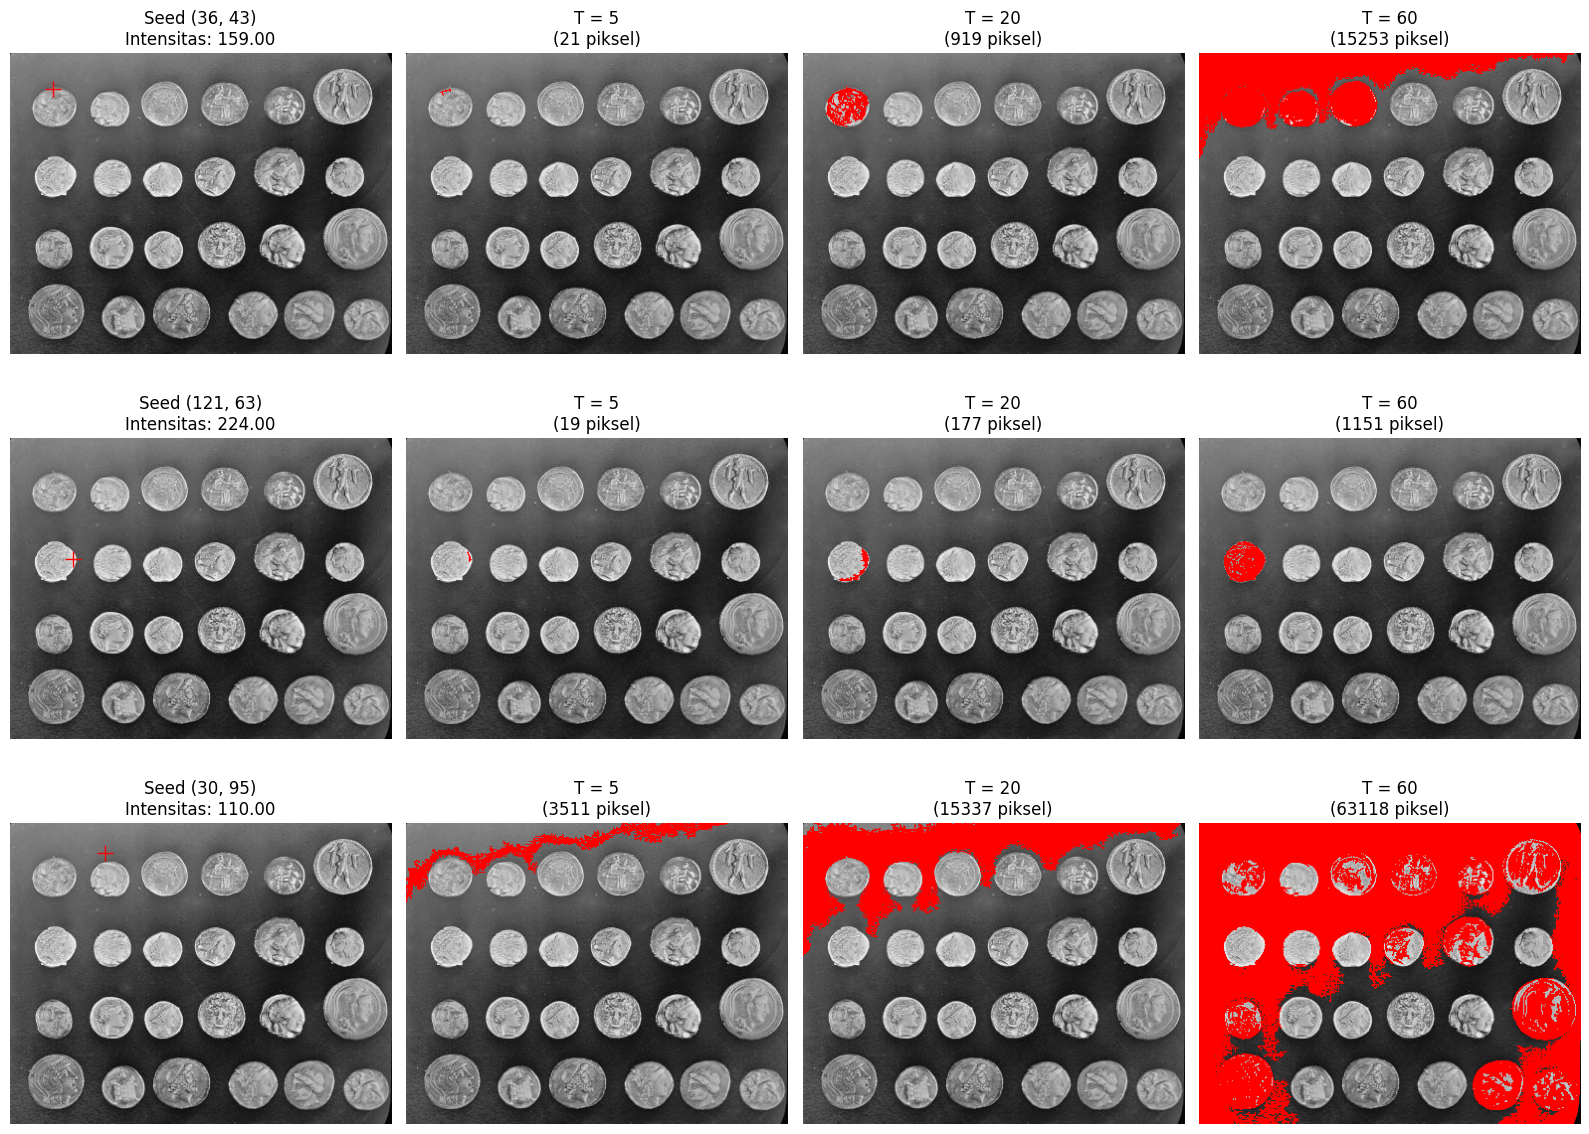

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from collections import deque

img = data.coins()
seeds = [
    (36, 43),
    (121, 63),
    (30, 95)
]

tolerances = [5, 20, 60]

function_region_growing = lambda image, seed, T: _region_growing_impl(image, seed, T)

def _region_growing_impl(image, seed, T):
    h, w = image.shape
    segmented = np.zeros((h, w), dtype=bool)
    visited = np.zeros((h, w), dtype=bool)

    seed_val = float(image[seed[0], seed[1]])
    queue = deque([seed])
    visited[seed[0], seed[1]] = True

    neighbors = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    while queue:
        r, c = queue.popleft()
        segmented[r, c] = True

        for dr, dc in neighbors:
            nr, nc = r + dr, c + dc
            if 0 <= nr < h and 0 <= nc < w and not visited[nr, nc]:
                if abs(float(image[nr, nc]) - seed_val) <= T:
                    visited[nr, nc] = True
                    queue.append((nr, nc))

    return segmented

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for i, seed in enumerate(seeds):
    axes[i, 0].imshow(img, cmap='gray')
    axes[i, 0].plot(seed[1], seed[0], 'r+', markersize=12)
    seed_intensity = img[seed[0], seed[1]]
    axes[i, 0].set_title(f"Seed ({seed[0]}, {seed[1]})\nIntensitas: {seed_intensity:.2f}")
    axes[i, 0].axis('off')

    for j, tol in enumerate(tolerances):
        mask = _region_growing_impl(img, seed, tol)
        pixel_count = np.sum(mask)

        overlay = np.stack([img, img, img], axis=-1)
        overlay[mask] = [255, 0, 0]

        axes[i, j + 1].imshow(overlay)
        axes[i, j + 1].set_title(f"T = {tol}\n({pixel_count} piksel)")
        axes[i, j + 1].axis('off')

plt.tight_layout()
plt.show()

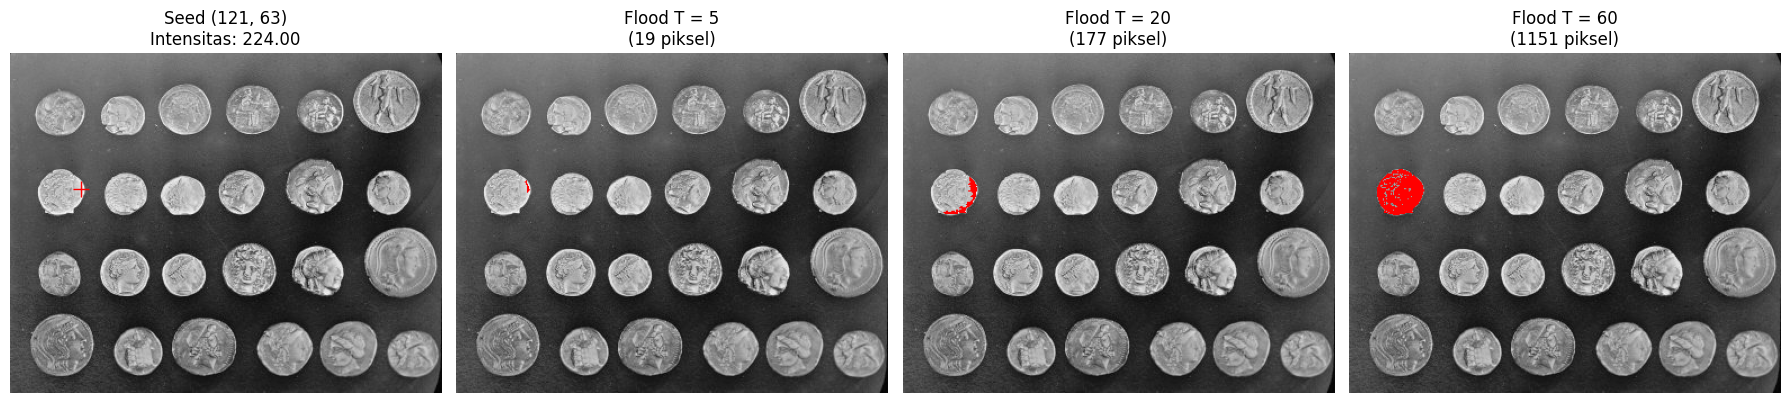

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.segmentation import flood

gray = data.coins()
seed = (121, 63)
tolerances = [5, 20, 60]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(gray, cmap='gray')
axes[0].plot(seed[1], seed[0], 'r+', markersize=12)
axes[0].set_title(f"Seed ({seed[0]}, {seed[1]})\nIntensitas: {gray[seed[0], seed[1]]:.2f}")
axes[0].axis('off')

for j, tol in enumerate(tolerances):
    region = flood(
        gray,
        seed_point=seed,
        tolerance=tol,
        connectivity=1
    )

    pixel_count = np.sum(region)

    overlay = np.stack([gray, gray, gray], axis=-1)
    overlay[region] = [255, 0, 0]

    axes[j + 1].imshow(overlay)
    axes[j + 1].set_title(f"Flood T = {tol}\n({pixel_count} piksel)")
    axes[j + 1].axis('off')

plt.tight_layout()
plt.show()

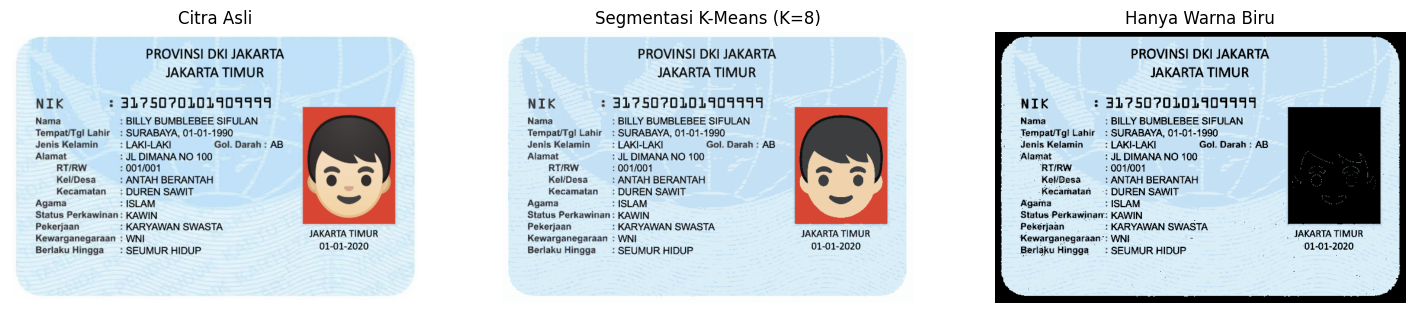

In [29]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

filename = '/content/drive/MyDrive/PCVK/Images/ktp_fulan.jpg'
img_bgr = cv.imread(filename)
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)

Z = img_rgb.reshape((-1, 3))
Z = np.float32(Z)

k = 8
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(Z)

labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)

segmented = centers[labels.flatten()]
segmented_img = segmented.reshape(img_rgb.shape)

hsv_img = cv.cvtColor(segmented_img, cv.COLOR_RGB2HSV)
H = hsv_img[:, :, 0]
S = hsv_img[:, :, 1]
V = hsv_img[:, :, 2]

kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))

hanya_biru = np.zeros_like(segmented_img)
hanya_biru[kelompok_biru] = segmented_img[kelompok_biru]

titles = ['Citra Asli', 'Segmentasi K-Means (K=8)', 'Hanya Warna Biru']
images = [img_rgb, segmented_img, hanya_biru]

plt.figure(figsize=(18, 5))
for i in range(len(images)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i])
    plt.title(titles[i])
    plt.axis('off')
plt.show()

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
=== TEKS OCR (BERWARNA) ===
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 31750?0101901411
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW : 001/001

KellDesa —— : ANTAH BERANTAH N 4

Kecamatan  : DUREN SAWIT t
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI SIata TOR
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020


=== TEKS OCR (OTSU) ===
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK : 31?507D101909919
kama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgi Lahu: SURABAYA, 01-01-1900
Jenis Kelamin LAKI-LAKI Gol. Daerah : AB
Alamat : JL DIMANA NO 100

RTRW : 0017001

KevDesa —: ANTAH BERANTAH d z )

Kecamatan: DUREN SAWIT
Status Perkawinan : KAWIN
Pekerjaan aan 8 KARYAWAN SWASTA TA TIMUR
Ber

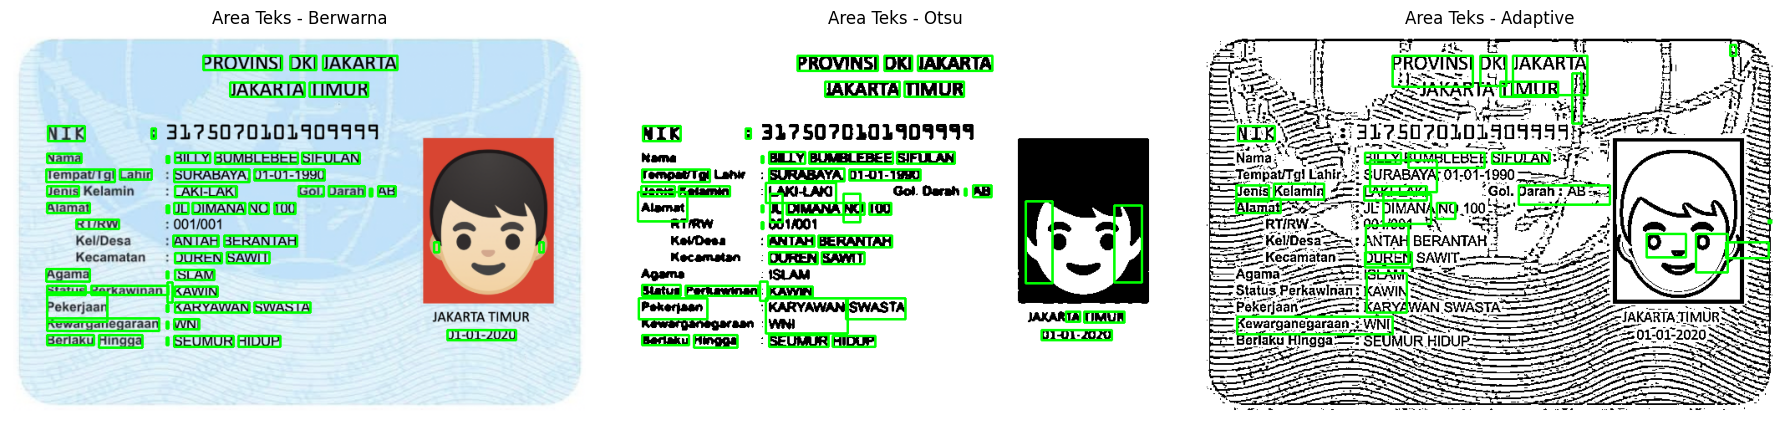

In [31]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
from PIL import Image

filename = '/content/drive/MyDrive/PCVK/Images/ktp_fulan.jpg'
img_bgr = cv.imread(filename)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

img_color = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)

blur = cv.GaussianBlur(img_gray, (5, 5), 0)
_, img_otsu = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

img_adaptive = cv.adaptiveThreshold(
    img_gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv.THRESH_BINARY, 11, 2
)

custom_config = r'--oem 3 --psm 6 -l ind'

text_color = pytesseract.image_to_string(img_color, config=custom_config)
text_otsu = pytesseract.image_to_string(img_otsu, config=custom_config)
text_adaptive = pytesseract.image_to_string(img_adaptive, config=custom_config)

print("=== TEKS OCR (BERWARNA) ===")
print(text_color)
print("\n=== TEKS OCR (OTSU) ===")
print(text_otsu)
print("\n=== TEKS OCR (ADAPTIVE) ===")
print(text_adaptive)

images = [img_color, cv.cvtColor(img_otsu, cv.COLOR_GRAY2RGB), cv.cvtColor(img_adaptive, cv.COLOR_GRAY2RGB)]
titles = ['Area Teks - Berwarna', 'Area Teks - Otsu', 'Area Teks - Adaptive']

plt.figure(figsize=(18, 6))
for idx, img in enumerate(images):
    d = pytesseract.image_to_data(img, output_type=pytesseract.Output.DICT, config=custom_config)
    img_box = img.copy()

    n_boxes = len(d['text'])
    for i in range(n_boxes):
        conf = int(d['conf'][i])
        if conf > 60:
            (x, y, w, h) = (d['left'][i], d['top'][i], d['width'][i], d['height'][i])
            img_box = cv.rectangle(img_box, (x, y), (x + w, y + h), (0, 255, 0), 2)

    plt.subplot(1, 3, idx + 1)
    plt.imshow(img_box)
    plt.title(titles[idx])
    plt.axis('off')

plt.tight_layout()
plt.show()